# FleetSync ML Engine: Random Forest (Base Model)
**ICS 3202 [Aug-Nov 2026] | Semester Project Deliverable 2**

Group members:
Anthony Mutua
Emmanuel Bosire
Gloria Muluka

## 1. Problem and how it fits the app
FleetSync consists of a mobile application used by drivers, which gathers information about their trips, distance traveled and issues appearing while driving. 
The goal of the algorithm using machine learning technology is to solve the following problem during the pre-shift vehicle examination:

> Based on the information available for the vehicle (the distance traveled, age, service history, identified issues, condition of wheels), does it require any maintenance?

- ML task: supervised binary classification (target = Need_Maintenance; 1 – needs maintenance, 0 - does not).
- Base algorithm: **Random forest** (A lot of Decision trees making voting).
- Output of the application: the card shows “Maintenance needed: Yes or No” indicating a respective probability on the driver’s screen before the start of driving. 
- Link to driver’s application: `Reported_Issues` processed automatically through the one-click issue reporting in the app.

Notebook roadmap: (2) Data cleansing, (3) Exploration of data with observations, (4) Modeling approach with validity checks, (5) Evaluation, (6) Additional validity checks, (7) Plan for further validations with other models, (8) Conclusions and limitations.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     RandomizedSearchCV, validation_curve)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_auc_score, RocCurveDisplay, accuracy_score, f1_score,
                             recall_score, precision_score)

RANDOM_STATE = 42          # fixed so results can be reproduced
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

Matplotlib is building the font cache; this may take a moment.


## 2. Data cleaning: from raw file to modelling dataset
The steps below follow the order we worked in. Each step has a short note on **what we checked** and **what we decided**.

### 2.1 Load the raw data
The file has a hidden "byte-order mark" at its start, so we read it with `utf-8-sig`. Otherwise the first column name would be read incorrectly.

In [2]:
raw = pd.read_csv("train_set.csv", encoding="utf-8-sig")
print("Shape (rows, columns):", raw.shape)
raw.head()

Shape (rows, columns): (56697, 16)


,Vehicle_Model,Mileage,Maintenance_History,Reported_Issues,Vehicle_Age,Fuel_Type,Transmission_Type,Engine_Size,From last service,Owner_Type,Service_History,Accident_History,Fuel_Efficiency,Tire_Condition,Intensity,Need_Maintenance
0,Van,30107,Average,5,3,Electric,Automatic,2000,167,First,1,1,16.593869,Good,10035.666667,1
1,Van,33027,Average,3,1,Electric,Automatic,1000,143,Third,3,0,11.014727,New,33027.000000,1
2,Motorcycle,64011,Good,2,8,Petrol,Manual,2000,62,First,2,1,19.733278,Good,8001.375000,1
3,Car,51867,Poor,0,1,Electric,Manual,1500,323,First,8,0,13.371100,Good,51867.000000,0
4,SUV,36403,Good,0,9,Diesel,Manual,1500,180,Second,4,2,19.729747,New,3883.476963,0


### 2.2 First look: column types, missing values, duplicates

In [3]:
print(raw.dtypes)
print("\nMissing values per column:\n", raw.isna().sum())
print("\nDuplicate rows:", raw.duplicated().sum())

Vehicle_Model              str
Mileage                  int64
Maintenance_History        str
Reported_Issues          int64
Vehicle_Age              int64
Fuel_Type                  str
Transmission_Type          str
Engine_Size              int64
From last service        int64
Owner_Type                 str
Service_History          int64
Accident_History         int64
Fuel_Efficiency        float64
Tire_Condition             str
Intensity              float64
Need_Maintenance         int64
dtype: object

Missing values per column:
 Vehicle_Model          0
Mileage                0
Maintenance_History    0
Reported_Issues        0
Vehicle_Age            0
Fuel_Type              0
Transmission_Type      0
Engine_Size            0
From last service      0
Owner_Type             0
Service_History        0
Accident_History       0
Fuel_Efficiency        0
Tire_Condition         0
Intensity              0
Need_Maintenance       0
dtype: int64

Duplicate rows: 0


**Finding:** there are no missing values and no duplicate rows, so nothing needs filling in or removing at this stage.
Numbers are stored as numbers and text as text.

### 2.3 Tidy the column names
`From last service` has spaces, which makes code awkward and error-prone. We rename it to `Since_Last_Service`.
We do **not** assume its unit (the source does not say; values range from 57 to 392, probably days), so the name stays neutral.

In [4]:
df = raw.copy()
df.columns = df.columns.str.strip().str.replace(" ", "_")
df = df.rename(columns={"From_last_service": "Since_Last_Service"})
list(df.columns)

['Vehicle_Model',
 'Mileage',
 'Maintenance_History',
 'Reported_Issues',
 'Vehicle_Age',
 'Fuel_Type',
 'Transmission_Type',
 'Engine_Size',
 'Since_Last_Service',
 'Owner_Type',
 'Service_History',
 'Accident_History',
 'Fuel_Efficiency',
 'Tire_Condition',
 'Intensity',
 'Need_Maintenance']

### 2.4 Check categorical columns for inconsistent labels
Typos or different spellings of the same category (e.g. "petrol" vs "Petrol ") would silently split one category into two.

In [5]:
cat_cols = df.select_dtypes(include="object").columns.tolist()
for c in cat_cols:
    df[c] = df[c].str.strip()          # remove stray spaces (no effect if none)
    print(f"{c}: {sorted(df[c].unique())}")

Vehicle_Model: ['Bus', 'Car', 'Motorcycle', 'SUV', 'Truck', 'Van']
Maintenance_History: ['Average', 'Good', 'Poor']
Fuel_Type: ['Diesel', 'Electric', 'Petrol']
Transmission_Type: ['Automatic', 'Manual']
Owner_Type: ['First', 'Second', 'Third']
Tire_Condition: ['Good', 'New', 'Worn Out']


**Finding:** every categorical column has a small set of clean labels. No fixes needed beyond trimming spaces.

### 2.5 Sanity-check numeric ranges and look for outliers
We check that values are realistic (no negative mileage, ages of zero, etc.) and use the **IQR rule** (values beyond 1.5 x IQR from the quartiles)
to count potential outliers.

In [6]:
num_cols = df.select_dtypes(include="number").columns.drop("Need_Maintenance").tolist()
display(df[num_cols].describe().T[["min", "25%", "50%", "75%", "max"]])

rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum()
    rows.append((c, n_out, round(100 * n_out / len(df), 2)))
pd.DataFrame(rows, columns=["column", "IQR outliers", "% of rows"])

,min,25%,50%,75%,max
Mileage,30003.000000,42386.000000,54707.000000,67340.000000,80000.000000
Reported_Issues,0.000000,1.000000,2.000000,3.000000,5.000000
Vehicle_Age,1.000000,3.000000,5.000000,8.000000,10.000000
Engine_Size,800.000000,1000.000000,1500.000000,2000.000000,2500.000000
Since_Last_Service,57.000000,142.000000,223.000000,308.000000,392.000000
Service_History,1.000000,3.000000,5.000000,8.000000,10.000000
Accident_History,0.000000,0.000000,1.000000,2.000000,3.000000
Fuel_Efficiency,10.000098,12.503127,15.004374,17.457924,19.999968
Intensity,3000.500000,6803.300000,10015.000000,18173.165165,79990.000000


,column,IQR outliers,% of rows
0,Mileage,0,0.00
1,Reported_Issues,0,0.00
2,Vehicle_Age,0,0.00
3,Engine_Size,0,0.00
4,Since_Last_Service,0,0.00
5,Service_History,0,0.00
6,Accident_History,0,0.00
7,Fuel_Efficiency,0,0.00
8,Intensity,6053,10.68


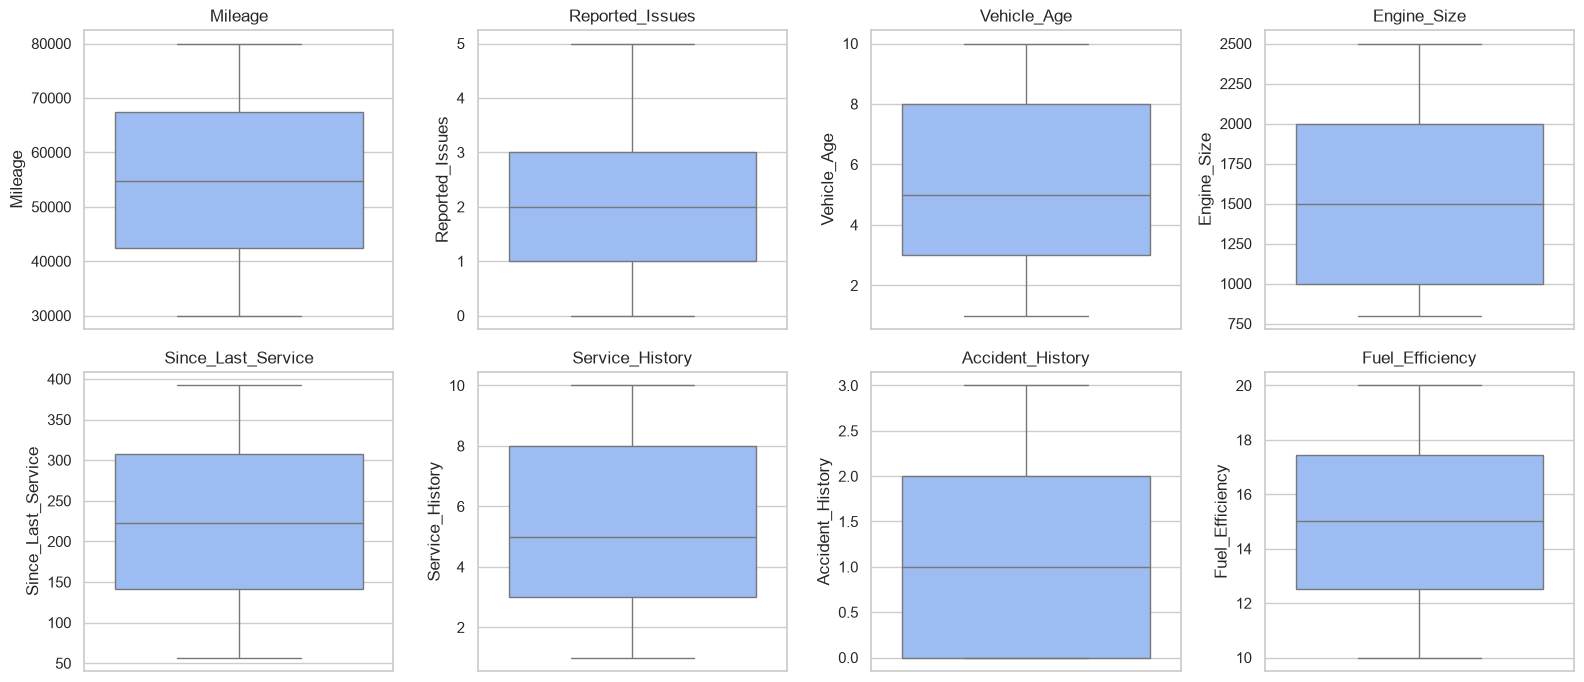

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(y=df[c], ax=ax, color="#8FB8FF")
    ax.set_title(c)
plt.tight_layout(); plt.show()

**Decision:** all values are inside realistic ranges (e.g. mileage 30,000-80,000, age 1-10 years). Only `Intensity` has IQR-flagged values.
It is a ratio-type column, so a long tail is expected rather than a data error. We **keep all rows**. Removing them would throw away valid vehicles
and the Random Forest is not sensitive to extreme values (trees split on thresholds, not distances).

### 2.6 Check for redundant or "too good to be true" columns
Two things can quietly damage a model: columns that are just a re-calculation of another column, and columns that leak the answer.

In [8]:
ratio = df["Mileage"] / df["Vehicle_Age"]
share_match = np.isclose(df["Intensity"], ratio).mean()
print(f"Intensity equals Mileage / Vehicle_Age in {share_match:.1%} of rows")
print("Correlation of Intensity with Mileage:", round(df[['Intensity','Mileage']].corr().iloc[0,1], 3))

Intensity equals Mileage / Vehicle_Age in 77.3% of rows
Correlation of Intensity with Mileage: 0.272


**Finding:** `Intensity` is (approximately) mileage per year of age, so it is a derived "how hard is the vehicle used" feature.
It is not a copy of the target, so it is **not leakage**. We keep it as a usage-intensity feature and check its real contribution later using permutation importance (section 5).

### 2.7 Final dataset for modelling
- Target: `Need_Maintenance` (0/1).
- 8 numeric features, 6 categorical features (`Vehicle_Model`, `Maintenance_History`, `Fuel_Type`, `Transmission_Type`, `Owner_Type`, `Tire_Condition`).
- Categorical columns are converted to numbers by **one-hot encoding** inside the modelling pipeline (section 4).
- **No scaling** is applied: Random Forest splits on thresholds, so feature scale does not matter.
- The cleaning is minimal because the raw data was already tidy. This is reported honestly rather than inventing steps.

In [9]:
df.to_csv("cleaned_vehicle_maintenance.csv", index=False)
print("Saved cleaned dataset:", df.shape)
TARGET = "Need_Maintenance"
cat_features = df.select_dtypes(include="object").columns.tolist()
num_features = df.select_dtypes(include="number").columns.drop(TARGET).tolist()
print("Numeric features:", num_features)
print("Categorical features:", cat_features)

Saved cleaned dataset: (56697, 16)
Numeric features: ['Mileage', 'Reported_Issues', 'Vehicle_Age', 'Engine_Size', 'Since_Last_Service', 'Service_History', 'Accident_History', 'Fuel_Efficiency', 'Intensity']
Categorical features: ['Vehicle_Model', 'Maintenance_History', 'Fuel_Type', 'Transmission_Type', 'Owner_Type', 'Tire_Condition']


## 3. Exploratory Data Analysis (EDA)
Goal: understand which vehicle details are linked to needing maintenance, and spot problems before modelling.

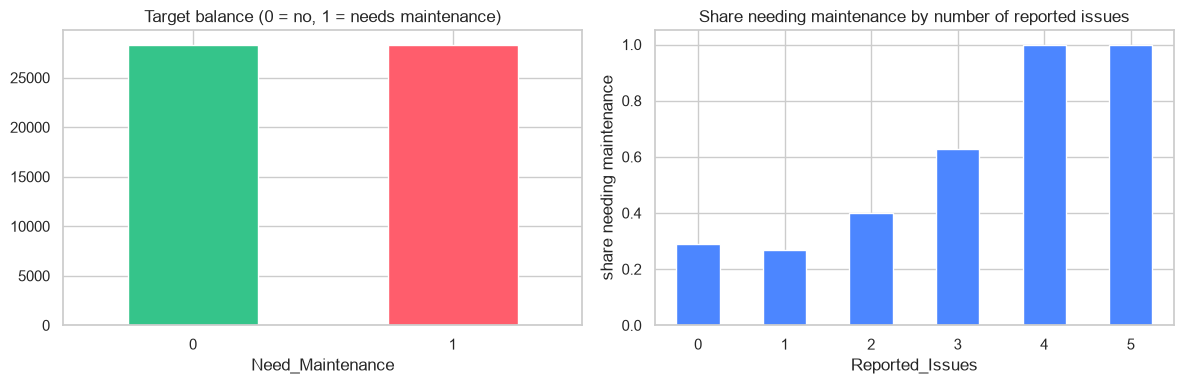

Need_Maintenance
1    0.5
0    0.5
Name: proportion, dtype: float64

Share needing maintenance by Reported_Issues:
 Reported_Issues
0    0.290
1    0.268
2    0.402
3    0.629
4    1.000
5    1.000
Name: Need_Maintenance, dtype: float64


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df[TARGET].value_counts().sort_index().plot(kind="bar", ax=axes[0], color=["#35C48A", "#FF5D6C"])
axes[0].set_title("Target balance (0 = no, 1 = needs maintenance)")
axes[0].set_xticklabels(["0", "1"], rotation=0)
rate = df.groupby("Reported_Issues")[TARGET].mean()
rate.plot(kind="bar", ax=axes[1], color="#4C86FF")
axes[1].set_title("Share needing maintenance by number of reported issues")
axes[1].set_ylabel("share needing maintenance"); axes[1].set_xticklabels(rate.index, rotation=0)
plt.tight_layout(); plt.show()
print(df[TARGET].value_counts(normalize=True).round(3))
print("\nShare needing maintenance by Reported_Issues:\n", rate.round(3))

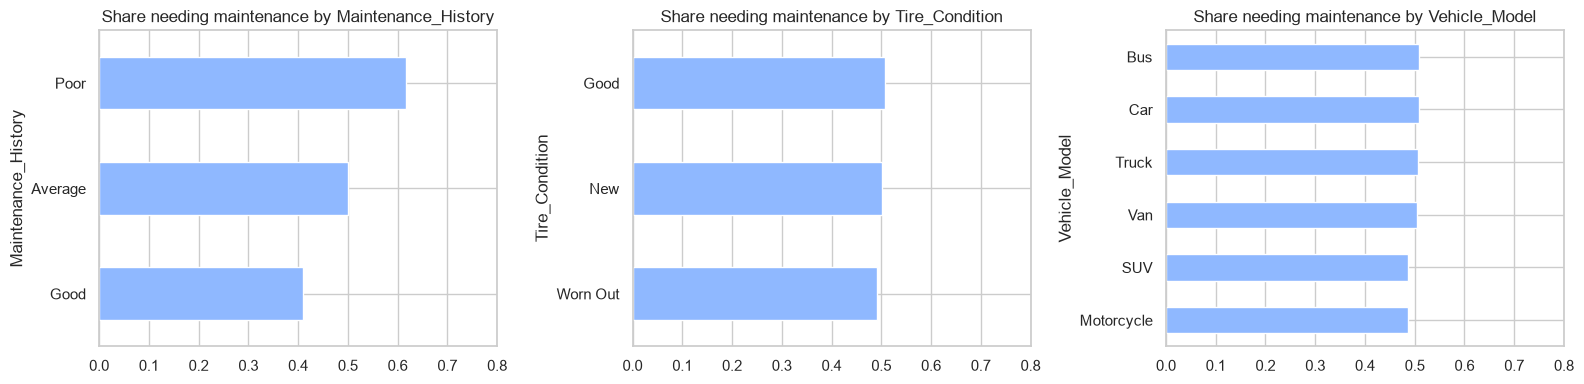

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ["Maintenance_History", "Tire_Condition", "Vehicle_Model"]):
    s = df.groupby(c)[TARGET].mean().sort_values()
    s.plot(kind="barh", ax=ax, color="#8FB8FF")
    ax.set_title(f"Share needing maintenance by {c}")
    ax.set_xlim(0, 0.8)
plt.tight_layout(); plt.show()

Correlation of each numeric feature with the target:
 Engine_Size          -0.001
Since_Last_Service    0.001
Fuel_Efficiency       0.001
Vehicle_Age           0.003
Mileage               0.003
Intensity             0.005
Accident_History      0.105
Service_History       0.138
Reported_Issues       0.525
Name: Need_Maintenance, dtype: float64


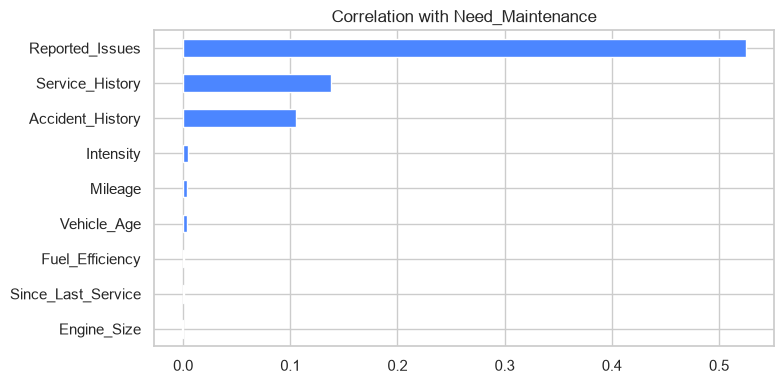

In [12]:
corr = df[num_features + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()
print("Correlation of each numeric feature with the target:\n", corr.round(3))
plt.figure(figsize=(8, 4))
corr.plot(kind="barh", color="#4C86FF")
plt.title("Correlation with Need_Maintenance"); plt.tight_layout(); plt.show()

### EDA observations
1. The classes are balanced. Vehicles needing maintenance are 50.0% of the data and the rest 50.0%. Accuracy is therefore a fair metric, and no resampling is needed.
   A model that always guesses one class would score about 50%, which is our benchmark to beat.
2. `Reported_Issues` is the strongest signal. The share needing maintenance is about 29% with 0 issues, 27% with 1, 40% with 2, 63% with 3, and 100% with 4 or 5 issues
   (correlation about 0.53, far above any other numeric feature). This links directly to the driver app's one-tap fault reporting.
3. Maintenance history matters. Vehicles with "Poor" history need maintenance about 62% of the time, "Average" about 50% and "Good" about 41%.
   `Service_History` (about 0.14) and `Accident_History` (about 0.11) also have weaker positive links.
4. Several features show almost no link to the target on their own. `Mileage`, `Vehicle_Age`, `Engine_Size`, `Fuel_Efficiency`, `Since_Last_Service`, `Intensity`
   all have correlations near 0, and `Tire_Condition`, `Fuel_Type`, `Vehicle_Model` and `Transmission_Type` give almost the same rate (about 49-51%) in every category.
   Surprisingly, "Worn Out" tyres do not need maintenance more often than "New" ones in this data. This suggests the data is simulated, which we state as a limitation.
5. The 4+ issues rule is almost deterministic. Every vehicle with 4 or 5 reported issues needs maintenance, so the model will find this easy.
   We test how much the model depends on it in section 6.

## 4. Modelling approach (base model: Random Forest)

**Plan**
1. Hold out **20% as a final test set** that is never used for tuning. Use a *stratified* split so both sets keep the 50/50 class balance.
2. Build a **pipeline** (encode categories, then Random Forest) so the same preparation is applied inside every cross-validation fold. This avoids leaking information from validation folds.
3. Compare to a **do-nothing baseline** (always predicts the most common class).
4. Run **5-fold stratified cross-validation** on the training data to measure how stable the performance is.
5. **Tune** the main Random Forest settings with cross-validation and use a **validation curve** to check for over-fitting.
6. Evaluate the final model **once** on the test set.

In [13]:
X = df.drop(columns=TARGET)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train class share:", y_train.mean().round(3), "| Test class share:", y_test.mean().round(3))

preprocess = ColumnTransformer([
    ("categories", OneHotEncoder(handle_unknown="ignore"), cat_features),
], remainder="passthrough")          # numeric columns pass through unchanged

def make_pipeline(model):
    return Pipeline([("prep", preprocess), ("model", model)])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
           "f1": "f1", "roc_auc": "roc_auc"}

def cv_report(pipe, name, X_=None, y_=None):
    X_ = X_train if X_ is None else X_
    y_ = y_train if y_ is None else y_
    res = cross_validate(pipe, X_, y_, cv=cv, scoring=scoring, return_train_score=True, n_jobs=-1)
    out = {m: (res[f"test_{m}"].mean(), res[f"test_{m}"].std()) for m in scoring}
    out["train_f1"] = (res["train_f1"].mean(), res["train_f1"].std())
    return pd.Series({k: f"{v[0]:.3f} +/- {v[1]:.3f}" for k, v in out.items()}, name=name)

Train: (45357, 15)  Test: (11340, 15)
Train class share: 0.5 | Test class share: 0.5


### 4.1 Baseline: how well does "always guess the most common class" do?

In [14]:
baseline = cv_report(make_pipeline(DummyClassifier(strategy="most_frequent")), "Dummy baseline")
baseline.to_frame().T

,accuracy,precision,recall,f1,roc_auc,train_f1
Dummy baseline,0.500 +/- 0.000,0.300 +/- 0.245,0.600 +/- 0.490,0.400 +/- 0.327,0.500 +/- 0.000,0.400 +/- 0.327


The dummy model scores **0.50 accuracy and 0.50 ROC-AUC**, which is the benchmark to beat. Its precision, recall and F1 swing between folds (large +/- values) because with a perfect 50/50 split it is arbitrary which class counts as "most common" in each fold, so only accuracy and ROC-AUC are meaningful here.

### 4.2 Base Random Forest with default settings (5-fold cross-validation)
Each fold trains on 80% of the training data and is scored on the remaining 20%. The score is reported as **mean +/- standard deviation**.
A small standard deviation means the result is stable and not down to a lucky split.
`train_f1` is shown so we can compare it with the validation F1 to spot over-fitting.

In [15]:
rf_default = make_pipeline(RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1))
default_report = cv_report(rf_default, "RF default")
pd.concat([baseline, default_report], axis=1).T

,accuracy,precision,recall,f1,roc_auc,train_f1
Dummy baseline,0.500 +/- 0.000,0.300 +/- 0.245,0.600 +/- 0.490,0.400 +/- 0.327,0.500 +/- 0.000,0.400 +/- 0.327
RF default,0.820 +/- 0.002,0.901 +/- 0.002,0.719 +/- 0.007,0.800 +/- 0.003,0.887 +/- 0.002,1.000 +/- 0.000


### 4.3 Is the forest over-fitting? Validation curve on tree depth
Trees that are allowed to grow very deep can memorise the training data. We vary `max_depth` and compare the **training score** with the **cross-validated score**.
When the two lines drift far apart, the model is over-fitting.
(This is the Random Forest equivalent of using the elbow method for K-means: we look for the point where improvement stops.)

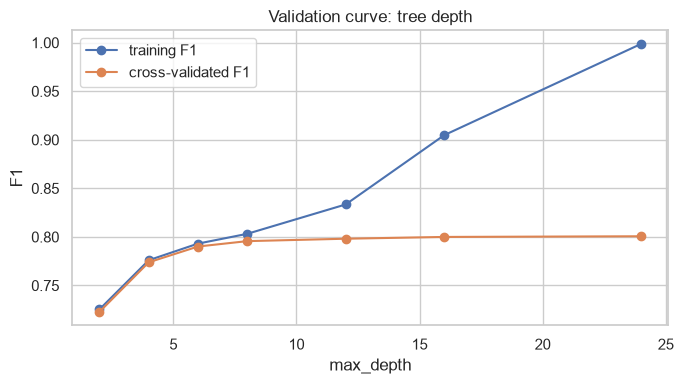

,max_depth,train_f1,cv_f1
0,2,0.725,0.723
1,4,0.776,0.774
2,6,0.793,0.790
3,8,0.803,0.796
4,12,0.833,0.798
5,16,0.905,0.800
6,24,0.999,0.801


In [16]:
depths = [2, 4, 6, 8, 12, 16, 24]
train_s, val_s = validation_curve(
    make_pipeline(RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)),
    X_train, y_train, param_name="model__max_depth", param_range=depths,
    cv=3, scoring="f1", n_jobs=1)

plt.figure(figsize=(7, 4))
plt.plot(depths, train_s.mean(axis=1), "o-", label="training F1")
plt.plot(depths, val_s.mean(axis=1), "o-", label="cross-validated F1")
plt.xlabel("max_depth"); plt.ylabel("F1"); plt.title("Validation curve: tree depth")
plt.legend(); plt.tight_layout(); plt.show()
pd.DataFrame({"max_depth": depths, "train_f1": train_s.mean(axis=1).round(3),
              "cv_f1": val_s.mean(axis=1).round(3)})

**How to read it:** cross-validated F1 stops improving after a modest depth, while training F1 keeps climbing towards 1.0.
The growing gap is over-fitting, so we limit depth (and leaf size) in the tuning step rather than letting trees grow without limit.

### 4.4 Tune the main settings (randomized search with cross-validation)
We search over the number of trees, tree depth, the minimum samples per leaf and how many features each split may consider.
Each candidate is scored by 3-fold cross-validation on the **training set only**, using **F1** (balances precision and recall).

In [17]:
param_dist = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [6, 8, 10, 12, 16],
    "model__min_samples_leaf": [1, 3, 5, 10],
    "model__max_features": ["sqrt", "log2", 0.5],
}
search = RandomizedSearchCV(
    make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
    param_distributions=param_dist, n_iter=8, scoring="f1",
    cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE, n_jobs=1)
search.fit(X_train, y_train)

print("Best settings:", search.best_params_)
print("Best cross-validated F1:", round(search.best_score_, 3))
pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "rank_test_score"]].sort_values("rank_test_score").head(5)

Best settings: {'model__n_estimators': 200, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': 16}
Best cross-validated F1: 0.8


,params,mean_test_score,rank_test_score
4,"{'model__n_estimators': 200, 'model__min_sampl...",0.800014,1
7,"{'model__n_estimators': 300, 'model__min_sampl...",0.797699,2
2,"{'model__n_estimators': 100, 'model__min_sampl...",0.797384,3
3,"{'model__n_estimators': 100, 'model__min_sampl...",0.797218,4
6,"{'model__n_estimators': 100, 'model__min_sampl...",0.795481,5


In [18]:
rf_tuned = search.best_estimator_
tuned_report = cv_report(rf_tuned, "RF tuned")
pd.concat([baseline, default_report, tuned_report], axis=1).T

,accuracy,precision,recall,f1,roc_auc,train_f1
Dummy baseline,0.500 +/- 0.000,0.300 +/- 0.245,0.600 +/- 0.490,0.400 +/- 0.327,0.500 +/- 0.000,0.400 +/- 0.327
RF default,0.820 +/- 0.002,0.901 +/- 0.002,0.719 +/- 0.007,0.800 +/- 0.003,0.887 +/- 0.002,1.000 +/- 0.000
RF tuned,0.821 +/- 0.003,0.908 +/- 0.003,0.715 +/- 0.007,0.800 +/- 0.004,0.888 +/- 0.002,0.896 +/- 0.002


**Result:** the tuned forest (200 trees, depth limit 16) scores the same as the default one in cross-validation (F1 about 0.80 for both, difference well inside the +/- spread), so tuning did **not** improve accuracy. What it did change is over-fitting: the default forest scores a perfect training F1 of 1.00 against 0.80 on validation, while the tuned forest has 0.90 against 0.80. We keep the tuned version because it generalises with a smaller gap, and report honestly that the default would perform just as well.

## 5. Evaluation on the held-out test set
The test set has not been used for any decision so far, so this is our best estimate of performance on new vehicles.

**Which metric matters?** For maintenance alerts, a **missed vehicle that needs maintenance (false negative)** is more costly than an unnecessary check (false positive).
So we pay special attention to **recall** alongside overall accuracy and F1.

                   precision    recall  f1-score   support

   No maintenance       0.76      0.93      0.84      5670
Needs maintenance       0.90      0.71      0.79      5670

         accuracy                           0.82     11340
        macro avg       0.83      0.82      0.82     11340
     weighted avg       0.83      0.82      0.82     11340

ROC-AUC: 0.885


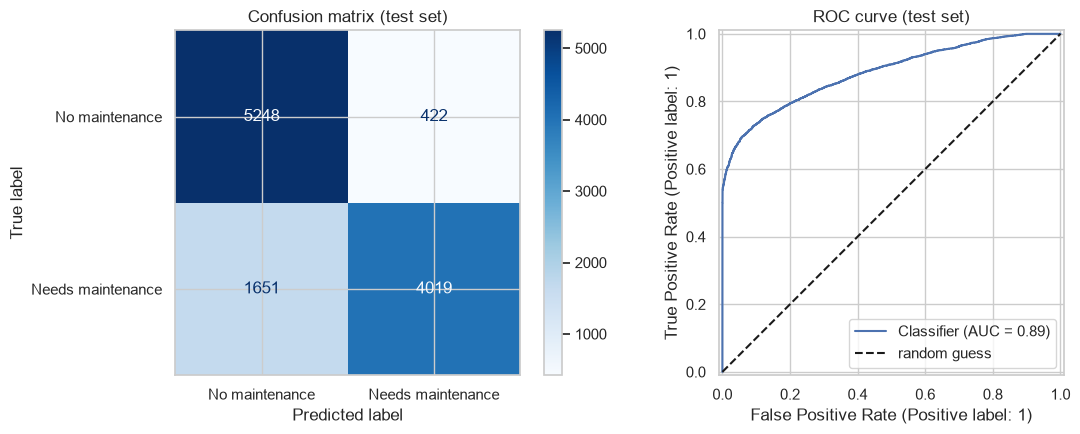

In [19]:
rf_tuned.fit(X_train, y_train)
y_pred = rf_tuned.predict(X_test)
y_prob = rf_tuned.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=["No maintenance", "Needs maintenance"]))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=axes[0], cmap="Blues",
                                        display_labels=["No maintenance", "Needs maintenance"])
axes[0].set_title("Confusion matrix (test set)")
RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="random guess"); axes[1].legend()
axes[1].set_title("ROC curve (test set)")
plt.tight_layout(); plt.show()

**Reading the test results (all numbers on 11,340 vehicles the model never saw):**
- Overall accuracy is about **82%** and ROC-AUC about **0.885**, in line with the cross-validation scores, so there is no sign that the model only memorised the training data.
- The model is **careful but cautious**: when it says "needs maintenance" it is right about 90% of the time (precision), but it only catches about **71%** of the vehicles that really need maintenance (recall). About 29% are missed.
- For a maintenance alert, missed vehicles are the costly mistake, so a next step is to **lower the decision threshold** (for example flag a vehicle when the predicted probability is above 0.35 instead of 0.5) to trade some precision for higher recall. We will tune that for the final version.

### 5.1 Which features does the forest rely on?
Two views: **impurity importance** (how much each feature helped the trees split) and **permutation importance**
(how much the test score drops when that feature is shuffled; this is the more trustworthy one).

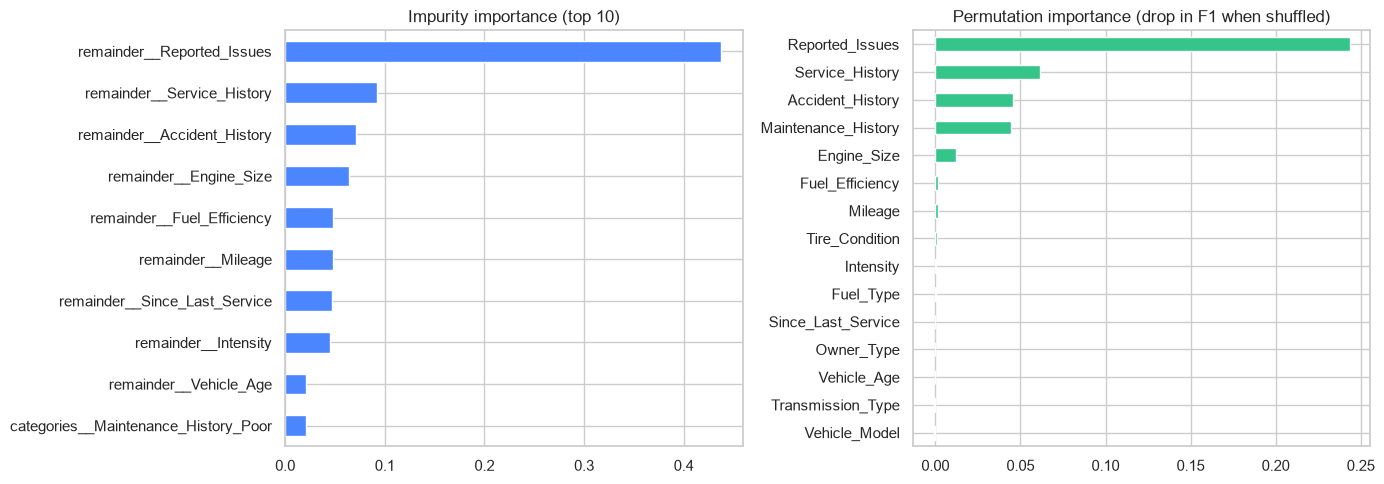

Reported_Issues        0.2434
Service_History        0.0615
Accident_History       0.0459
Maintenance_History    0.0445
Engine_Size            0.0123
Fuel_Efficiency        0.0017
Mileage                0.0014
Tire_Condition         0.0008
Intensity              0.0002
Fuel_Type              0.0001
Since_Last_Service    -0.0002
Owner_Type            -0.0002
Vehicle_Age           -0.0003
Transmission_Type     -0.0008
Vehicle_Model         -0.0010
dtype: float64

In [20]:
prep_fitted = rf_tuned.named_steps["prep"]
feat_names = prep_fitted.get_feature_names_out()
imp = pd.Series(rf_tuned.named_steps["model"].feature_importances_, index=feat_names).sort_values(ascending=False)

perm = permutation_importance(rf_tuned, X_test, y_test, n_repeats=5, scoring="f1",
                              random_state=RANDOM_STATE, n_jobs=1)
perm_s = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
imp.head(10)[::-1].plot(kind="barh", ax=axes[0], color="#4C86FF")
axes[0].set_title("Impurity importance (top 10)")
perm_s[::-1].plot(kind="barh", ax=axes[1], color="#35C48A")
axes[1].set_title("Permutation importance (drop in F1 when shuffled)")
plt.tight_layout(); plt.show()
perm_s.round(4)

**Reading this:** `Reported_Issues` dominates (shuffling it drops test F1 by about 0.24), followed by `Service_History`, `Accident_History` and `Maintenance_History` (about 0.04-0.06 each). Everything else is near zero, including `Mileage`, `Vehicle_Age`, `Since_Last_Service`, `Tire_Condition` and our derived `Intensity` column, which means the model is effectively built on four features. `Intensity` adds nothing measurable, so it is a candidate to drop in the final version; we kept it here so the decision is shown with evidence.

## 6. Extra checks on whether the results are trustworthy
These small experiments test whether the good score could be an accident or hide a problem.

**Check A: shuffled labels.** If we randomly shuffle the target, the model should drop to about 50%. If it does not, something leaks.

**Check B: remove `Reported_Issues`.** Shows how much the model depends on the single strongest feature, and how it would behave if drivers do not report issues.

In [21]:
rng = np.random.RandomState(RANDOM_STATE)
y_shuffled = pd.Series(rng.permutation(y_train.values), index=y_train.index)
shuffled = cv_report(rf_tuned, "A: shuffled labels", y_=y_shuffled)

X_train_no = X_train.drop(columns="Reported_Issues")
cat_f, num_f = cat_features, [c for c in num_features if c != "Reported_Issues"]
prep_no = ColumnTransformer([("categories", OneHotEncoder(handle_unknown="ignore"), cat_f)], remainder="passthrough")
rf_no = Pipeline([("prep", prep_no), ("model", RandomForestClassifier(**{k.replace("model__", ""): v for k, v in search.best_params_.items()},
                                                                       random_state=RANDOM_STATE, n_jobs=-1))])
no_issues = cv_report(rf_no, "B: without Reported_Issues", X_=X_train_no)

pd.concat([tuned_report, shuffled, no_issues], axis=1).T

,accuracy,precision,recall,f1,roc_auc,train_f1
RF tuned,0.821 +/- 0.003,0.908 +/- 0.003,0.715 +/- 0.007,0.800 +/- 0.004,0.888 +/- 0.002,0.896 +/- 0.002
A: shuffled labels,0.497 +/- 0.006,0.497 +/- 0.006,0.490 +/- 0.005,0.493 +/- 0.004,0.496 +/- 0.003,0.999 +/- 0.000
B: without Reported_Issues,0.675 +/- 0.004,0.703 +/- 0.003,0.605 +/- 0.007,0.651 +/- 0.005,0.757 +/- 0.004,0.894 +/- 0.002


**Interpretation:**
- **Check A (shuffled labels):** accuracy 0.50 and F1 0.49, which is exactly chance. So the real model's score comes from genuine patterns in the data, not from a leak or a coding mistake. (Its training F1 of 1.00 only shows the forest can memorise noise, which is why validation scores, not training scores, are what we trust.)
- **Check B (without `Reported_Issues`):** accuracy falls from 0.82 to about 0.68 and F1 from 0.80 to about 0.65. The model still beats chance using service, accident and maintenance history, but a large part of its power comes from reported issues. This supports the FleetSync design (drivers' reports are the key input) and warns that predictions will be weaker for vehicles whose drivers do not report problems.

## 7. Plan for validating the base model with other methods (Question 4)
To check that Random Forest is a sensible choice, and not just a lucky one, the group will build **other models that follow exactly the same process** and compare them:

| Step | Applied the same way to every model |
|---|---|
| Data | Same cleaned dataset, same 80/20 stratified split, same random seed |
| Preparation | Same one-hot encoding pipeline (with scaling added for KNN and Logistic Regression, which need it) |
| Validation | Same 5-fold stratified cross-validation on the training set |
| Metrics | Accuracy, precision, recall, F1, ROC-AUC (mean +/- standard deviation) |
| Final check | One evaluation on the same held-out test set |

**Candidate comparison models:** Gradient Boosting, Decision Tree (single tree), Logistic Regression (linear baseline), KNN (distance-based).

**How we will judge them:** a model is only "better" if its improvement is larger than the fold-to-fold spread (the +/- value).
If several models score similarly, we prefer the one that is simpler to explain and quicker to run in the app.
The results will be shown in one comparison table and bar chart (like Figure 6 in the reference paper).

The cell below is a **preview** run so the group can see the workflow works. The full comparison will be completed for the final notebook.

In [22]:
scaled_prep = ColumnTransformer([
    ("categories", OneHotEncoder(handle_unknown="ignore"), cat_features),
    ("numbers", StandardScaler(), num_features)])

models = {
    "Random Forest (tuned)": rf_tuned,
    "Gradient Boosting": make_pipeline(HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
    "Decision Tree (depth 6)": make_pipeline(DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE)),
    "Logistic Regression": Pipeline([("prep", scaled_prep), ("model", LogisticRegression(max_iter=2000))]),
    "KNN (k=15)": Pipeline([("prep", scaled_prep), ("model", KNeighborsClassifier(n_neighbors=15))]),
}
comparison = pd.concat([cv_report(m, n) for n, m in models.items()], axis=1).T
comparison[["accuracy", "precision", "recall", "f1", "roc_auc"]]

,accuracy,precision,recall,f1,roc_auc
Random Forest (tuned),0.821 +/- 0.003,0.908 +/- 0.003,0.715 +/- 0.007,0.800 +/- 0.004,0.888 +/- 0.002
Gradient Boosting,0.830 +/- 0.002,0.914 +/- 0.001,0.728 +/- 0.005,0.811 +/- 0.003,0.907 +/- 0.001
Decision Tree (depth 6),0.817 +/- 0.003,0.900 +/- 0.006,0.714 +/- 0.007,0.796 +/- 0.004,0.870 +/- 0.004
Logistic Regression,0.751 +/- 0.003,0.769 +/- 0.003,0.716 +/- 0.005,0.742 +/- 0.004,0.818 +/- 0.003
KNN (k=15),0.774 +/- 0.002,0.864 +/- 0.003,0.651 +/- 0.003,0.743 +/- 0.003,0.830 +/- 0.002


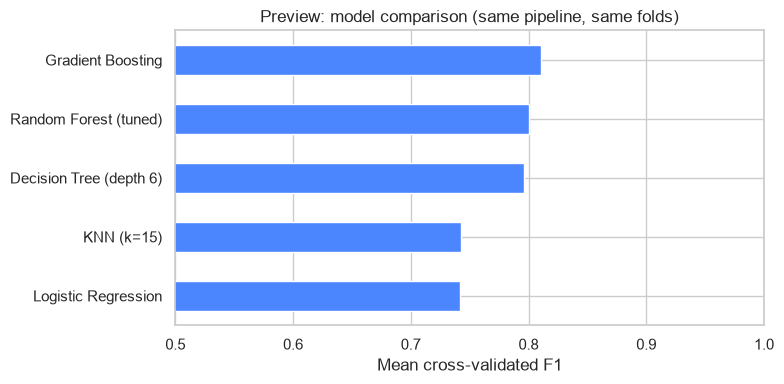

In [23]:
f1_means = comparison["f1"].str.split(" ").str[0].astype(float)
plt.figure(figsize=(8, 4))
f1_means.sort_values().plot(kind="barh", color="#4C86FF")
plt.xlabel("Mean cross-validated F1"); plt.title("Preview: model comparison (same pipeline, same folds)")
plt.xlim(0.5, 1.0); plt.tight_layout(); plt.show()

**What the preview shows:** the tree-based models (Gradient Boosting, Random Forest, Decision Tree) are close together at F1 of about 0.80-0.81, while Logistic Regression and KNN are clearly lower (about 0.74).
Gradient Boosting is slightly ahead (F1 0.811 and ROC-AUC 0.907 versus 0.800 and 0.888 for Random Forest), a small but real difference beyond the +/- spread. A single depth-6 tree comes within about 0.004 F1 of the forest.
We still use Random Forest as the base model because it is easy to explain, gives feature importances, and is only about one point behind. The final notebook will repeat this comparison with each model tuned in the same way.

## 8. Conclusions, limitations and next steps

**Conclusions**
- The cleaned dataset (about 56,700 vehicles, balanced classes) supports a Random Forest that reaches about 82% accuracy, F1 about 0.80 and ROC-AUC about 0.89, against a 50% baseline. This is confirmed by 5-fold cross-validation, a held-out test set and a shuffled-label check (which falls to 50%).
- The model catches about 71% of vehicles that need maintenance, so lowering the decision threshold is the main improvement to try.
- The most important input is `Reported_Issues`, which the FleetSync driver app captures directly. This ties the ML engine to the app's purpose.

**Limitations (to state openly when presenting)**
- The data appears **simulated**: many features such as tyre condition and mileage have no link to the target. Results show the workflow works, not real-world accuracy.
- Vehicles with 4 or more reported issues are always labelled "needs maintenance", and without `Reported_Issues` accuracy falls to about 68%, so much of the performance rests on one feature.
- Readings used by the model (such as reported issues, service history) must come from the app or the fleet records; the phone cannot measure them by itself.
- The meaning and unit of `Since_Last_Service` is assumed, not confirmed by the source.

**Next steps**
- Complete the full model comparison (section 7) for the final notebook.
- Save the final model and connect it to the mobile app's pre-start screen.

In [24]:
# Save the final trained model so the app/back-end can load it later
joblib.dump(rf_tuned, "rf_maintenance_model.joblib")
print("Saved: rf_maintenance_model.joblib")

Saved: rf_maintenance_model.joblib


## 9. Group contributions
| Member | Contribution |
|---|---|
| _(name)_ | _(e.g. data cleaning, EDA, modelling, evaluation, validation plan)_ |